In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import sqlite3
from scipy.stats import ttest_ind
import scipy.stats as stats
warnings.filterwarnings('ignore')

In [3]:
import pandas as pd

df = pd.read_csv(
    r"C:\Users\rohit\sales_master_data_cleaned.csv"
)

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (89316, 12)

Columns:
['city', 'state', 'order_status', 'order_date', 'order_id', 'product_id', 'seller_id', 'item_price', 'shipping_charges', 'item_revenue', 'payment_type', 'product_category_name']


,city,state,order_status,order_date,order_id,product_id,seller_id,item_price,shipping_charges,item_revenue,payment_type,product_category_name
0,varzea paulista,SP,delivered,2017-10-22 18:57:54,Axfy13Hk4PIk,90K0C1fIyQUf,ZWM05J9LcBSF,223.51,84.65,308.16,credit_card,toys
1,armacao dos buzios,RJ,delivered,2018-06-20 21:40:31,v6px92oS8cLG,qejhpMGGVcsl,IjlpYfhUbRQs,170.80,23.79,194.59,credit_card,watches_gifts
2,jandira,SP,delivered,2018-02-16 16:19:31,Ulpf9skrhjfm,qUS5d2pEAyxJ,77p2EYxcM9MD,64.40,17.38,81.78,credit_card,costruction_tools_garden
3,uberlandia,MG,delivered,2018-08-18 18:04:29,bwJVWupf2keN,639iGvMyv0De,jWzS0ayv9TGf,264.50,30.72,295.22,credit_card,toys
4,ilhabela,SP,delivered,2017-12-22 16:44:04,Dd0QnrMk9Cj5,1lycYGcsic2F,l1pYW6GBnPMr,779.90,30.66,810.56,credit_card,toys


In [7]:

# 1. Dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# 2. Data types
print("\n--- Data Types ---")
display(df.dtypes.to_frame(name="Data Type"))

# 3. True missing values
print("\n--- Missing Values ---")
display(
    df.isnull().sum()
       .to_frame(name="Missing Count")
       .query("`Missing Count` > 0")
)

# 4. Empty or whitespace-only strings
print("\n--- Blank Strings ---")
blank_counts = df.select_dtypes(include="object").apply(
    lambda col: col.str.strip().eq("").sum()
)
display(blank_counts[blank_counts > 0].to_frame(name="Blank Count"))

# 5. Duplicate rows
print("\nExact duplicate rows:", df.duplicated().sum())

# 6. Date validation
print("\nOrder date data type:", df["order_date"].dtype)

df["order_date"] = pd.to_datetime(
    df["order_date"], errors="coerce"
)

print("Invalid or missing dates:", df["order_date"].isna().sum())
print("Earliest order date:", df["order_date"].min())
print("Latest order date:", df["order_date"].max())


Rows: 89316
Columns: 12

--- Data Types ---


,Data Type
city,object
state,object
order_status,object
order_date,object
order_id,object
product_id,object
seller_id,object
item_price,float64
shipping_charges,float64
item_revenue,float64



--- Missing Values ---


,Missing Count



--- Blank Strings ---


,Blank Count



Exact duplicate rows: 0

Order date data type: object
Invalid or missing dates: 0
Earliest order date: 2016-09-04 21:15:19
Latest order date: 2018-09-03 09:06:57


EXPLORATORY DATA ANALYSIS
    previously we explored the different tables in the database to identify bthe variables, get their relationship, and how much and which one we need in the final table for analysis

    In this part , we will analyze the fianl table to get insights for the distribution of each column which will help us understand dta patterns,identify anomalies, and ensure data quality before moving to ahead with further analysis
    

In [8]:
df.describe()

,order_date,item_price,shipping_charges,item_revenue
count,89316,89316.000000,89316.000000,89316.000000
mean,2017-12-28 18:48:18.752742912,340.900543,44.283210,385.183753
min,2016-09-04 21:15:19,0.850000,0.000000,1.140000
25%,2017-09-08 16:33:39,59.650000,20.110000,107.710000
50%,2018-01-16 16:13:36,136.900000,35.055000,184.650000
75%,2018-05-02 12:20:40,399.200000,57.190000,437.860000
max,2018-09-03 09:06:57,6735.000000,409.680000,6738.820000
std,NaN,557.459897,37.672491,558.492266


In [9]:

# Numerical summary
numeric_cols = ["item_price", "shipping_charges", "item_revenue"]

print("--- Numerical Summary ---")
display(df[numeric_cols].describe().T)

# Check for zero and negative values
print("\n--- Zero and Negative Values ---")

value_checks = pd.DataFrame({
    "Zero Count": (df[numeric_cols] == 0).sum(),
    "Negative Count": (df[numeric_cols] < 0).sum(),
    "Unique Values": df[numeric_cols].nunique()
})

display(value_checks)

# Detect potential outliers using the IQR method
print("\n--- Potential Outliers (IQR Method) ---")

outlier_results = []

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outlier_count = (
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ).sum()

    outlier_results.append({
        "Column": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Potential Outliers": outlier_count,
        "Outlier Percentage": round(
            outlier_count / len(df) * 100, 2
        )
    })

display(pd.DataFrame(outlier_results).set_index("Column"))


--- Numerical Summary ---


,count,mean,std,min,25%,50%,75%,max
item_price,89316.0,340.900543,557.459897,0.85,59.65,136.900,399.20,6735.00
shipping_charges,89316.0,44.283210,37.672491,0.00,20.11,35.055,57.19,409.68
item_revenue,89316.0,385.183753,558.492266,1.14,107.71,184.650,437.86,6738.82



--- Zero and Negative Values ---


,Zero Count,Negative Count,Unique Values
item_price,0,0,5235
shipping_charges,22,0,6327
item_revenue,0,0,28613



--- Potential Outliers (IQR Method) ---


,Q1,Q3,IQR,Lower Bound,Upper Bound,Potential Outliers,Outlier Percentage
Column,,,,,,,
item_price,59.65,399.20,339.55,-449.675,908.525,5798,6.49
shipping_charges,20.11,57.19,37.08,-35.510,112.810,4615,5.17
item_revenue,107.71,437.86,330.15,-387.515,933.085,6131,6.86


In [12]:

# 1. Highest item prices
print("--- Top 10 Transactions by Item Price ---")
display(
    df.nlargest(10, "item_price")[
        [
            "order_date", "order_id", "product_id",
            "city", "order_status", "payment_type",
            "item_price", "shipping_charges", "item_revenue"
        ]
    ]
)

# 2. Highest shipping charges
print("\n--- Top 10 Transactions by Shipping Charges ---")
display(
    df.nlargest(10, "shipping_charges")[
        [
            "order_date", "order_id", "product_id",
            "city", "order_status",
            "item_price", "shipping_charges", "item_revenue"
        ]
    ]
)

# 3. Records with zero shipping charges
print("\n--- Zero Shipping Charge Records ---")
display(
    df.loc[
        df["shipping_charges"].eq(0),
        [
            "order_date", "order_id", "product_id",
            "order_status", "item_price",
            "shipping_charges", "item_revenue"
        ]
    ].head(10)
)

print(
    "Total records with zero shipping charges:",
    df["shipping_charges"].eq(0).sum()
)

# 4. Validate the revenue calculation
revenue_mismatches = (
    (df["item_price"] + df["shipping_charges"] - df["item_revenue"])
    .abs() > 0.01
).sum()

print("\nRevenue calculation mismatches:", revenue_mismatches)


--- Top 10 Transactions by Item Price ---


,order_date,order_id,product_id,city,order_status,payment_type,item_price,shipping_charges,item_revenue
45436,2017-11-29 21:24:02,SwjsVBeUO9OM,HiyKPuVcad18,osasco,delivered,credit_card,6735.0,3.82,6738.82
28299,2017-07-12 14:26:37,aPnggTzFcusk,7tZV2OpLVZHg,sao paulo,delivered,credit_card,6499.0,70.06,6569.06
15663,2018-06-26 21:10:19,l630bFlZYRb8,PCt0IOPoZaEj,sorocaba,delivered,voucher,4799.0,41.84,4840.84
26305,2018-06-05 15:30:41,PqT34ZL67pQW,AQWrDq9u91NE,prudentopolis,delivered,credit_card,4799.0,45.76,4844.76
28208,2018-03-20 14:13:19,8kitYsDqaIKp,KAJ0PDyJw1af,santa helena de minas,delivered,credit_card,4799.0,18.67,4817.67
61505,2018-06-26 21:10:19,HGcdGTihBo5U,PCt0IOPoZaEj,sorocaba,delivered,credit_card,4799.0,41.84,4840.84
70683,2018-06-26 21:10:19,aoNyeGNf0YTw,PCt0IOPoZaEj,sorocaba,delivered,voucher,4799.0,41.84,4840.84
33362,2017-08-25 13:46:45,UQkobvTX3cgs,ExkEUxZ1mmls,montes claros,delivered,wallet,4690.0,47.55,4737.55
86143,2018-03-01 21:54:32,fefqo629MT0H,3YSqUYHtn8v3,juiz de fora,delivered,credit_card,4690.0,47.55,4737.55
913,2017-09-04 11:10:54,zcRsep0OyoAO,nXZPk6g0AKxS,santo andre,delivered,credit_card,4590.0,8.26,4598.26



--- Top 10 Transactions by Shipping Charges ---


,order_date,order_id,product_id,city,order_status,item_price,shipping_charges,item_revenue
7660,2018-06-15 22:42:09,5zanSVBXs4VQ,Y0TFdzbMEGBQ,recife,delivered,280.00,409.68,689.68
13208,2017-09-13 07:59:23,0GQVdAatZtAz,3nFamKuMJOoh,assis,delivered,19.04,409.68,428.72
27141,2018-04-02 20:32:50,x4USDX1BHUtF,27O0he9UZll1,sao paulo,delivered,107.63,409.68,517.31
60466,2017-09-11 17:16:47,JMQKyT3azSs8,iFYDVo0NCTQu,itapetininga,delivered,19.04,409.68,428.72
62699,2018-05-04 09:01:21,nVccq3PAbw5D,mvCVjpSlN3OU,volta redonda,delivered,2221.00,409.68,2630.68
88435,2017-09-13 07:59:23,ihgoQUhKSH34,3nFamKuMJOoh,assis,delivered,19.04,409.68,428.72
10911,2017-10-11 19:31:22,rFMc2hRWsOnJ,8my0KrjzFiJz,salvador,delivered,47.91,375.28,423.19
41772,2017-04-22 18:49:48,YttaZgG7UQNz,BX36sAGRjWz1,penapolis,delivered,264.50,375.28,639.78
46048,2018-08-14 18:22:47,KCTaZyrf3ZMz,yifYVWda6kIz,sao bernardo do campo,delivered,116.91,375.28,492.19
5706,2017-04-18 17:23:33,pTmPRVaZ9sZB,Cb05otRAVof7,juazeiro,delivered,13.61,339.59,353.20



--- Zero Shipping Charge Records ---


,order_date,order_id,product_id,order_status,item_price,shipping_charges,item_revenue
3640,2017-11-11 15:53:40,XHMhpM4tloHq,zKVvPw7yAwu1,delivered,19.98,0.0,19.98
11818,2017-04-08 11:46:53,jTHvokgb0GEn,9ZIFmr723AZ0,delivered,148.50,0.0,148.50
13322,2017-12-13 07:40:14,WIHSQjiTK9qV,ZeMdY9hO43n5,delivered,100.00,0.0,100.00
13749,2017-06-08 19:14:02,9OgeeCb5UCkc,pseA9q0kudhV,delivered,495.95,0.0,495.95
19418,2017-06-12 13:53:19,Af5T1pjI84Rm,6Ww1i7qd1Zqu,delivered,71.80,0.0,71.80
21328,2018-01-04 14:35:44,bpsXjZjDXSm5,ZeMdY9hO43n5,delivered,100.00,0.0,100.00
25608,2017-06-19 02:15:55,vKowCiKqbDEc,bJWTdVsrXOgZ,delivered,128.99,0.0,128.99
30497,2017-02-06 16:37:37,3K75NUsqnm9S,5EWnZ1mRjH3i,delivered,91.33,0.0,91.33
40363,2017-09-19 20:01:20,8V2y12GkZ9hz,L2NBqZlceabM,delivered,71.80,0.0,71.80
49006,2018-02-03 20:29:25,Xk7Rvql1N5eu,0LTIekFGdhqg,delivered,159.90,0.0,159.90


Total records with zero shipping charges: 22

Revenue calculation mismatches: 0


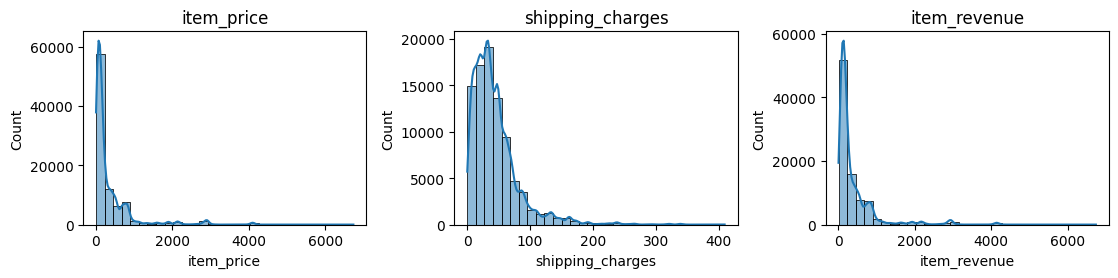

In [10]:
#distribution plot for numerical columns
numerical_cols= df.select_dtypes(include=np.number).columns

plt.figure(figsize=(15,10))
for i,col in enumerate(numerical_cols):
    plt.subplot(4,4,i+1) #to adjust the grid layout as needed
    sns.histplot(df[col], kde=True, bins=30)
    plt.title(col)
plt.tight_layout()
plt.show()
    


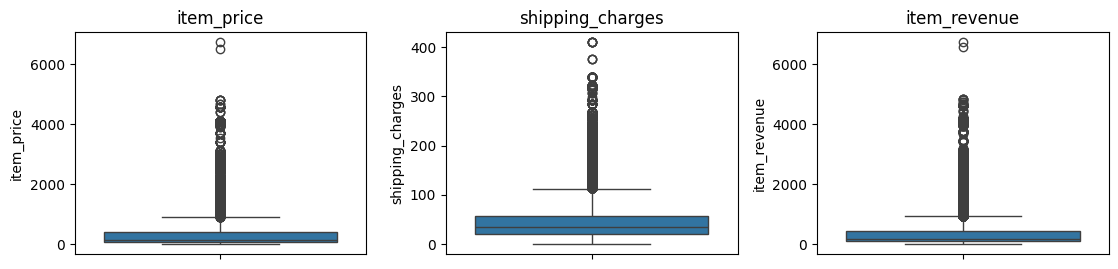

In [11]:
#outlier detection with boxplots
plt.figure(figsize=(15,10))
for i,col in enumerate(numerical_cols):
    plt.subplot(4,4,i+1)
    sns.boxplot(y=df[col])
    plt.title(col)
plt.tight_layout()
plt.show()

In [13]:

# Categorical columns to analyze
categorical_cols = [
    "order_status",
    "payment_type",
    "product_category_name",
    "state",
    "city"
]

for col in categorical_cols:
    print(f"\n--- {col.upper()} ---")
    print("Unique values:", df[col].nunique())

    display(
        df[col]
        .value_counts(dropna=False)
        .head(10)
        .rename_axis(col)
        .reset_index(name="transaction_rows")
    )



--- ORDER_STATUS ---
Unique values: 7


,order_status,transaction_rows
0,delivered,87428
1,shipped,936
2,canceled,409
3,processing,273
4,invoiced,266
5,unavailable,2
6,approved,2



--- PAYMENT_TYPE ---
Unique values: 4


,payment_type,transaction_rows
0,credit_card,65814
1,wallet,17302
2,voucher,4911
3,debit_card,1289



--- PRODUCT_CATEGORY_NAME ---
Unique values: 71


,product_category_name,transaction_rows
0,toys,67027
1,health_beauty,2351
2,bed_bath_table,2146
3,sports_leisure,1837
4,furniture_decor,1760
5,computers_accessories,1715
6,housewares,1340
7,watches_gifts,1196
8,telephony,912
9,auto,829



--- STATE ---
Unique values: 27


,state,transaction_rows
0,SP,37879
1,RJ,11578
2,MG,10334
3,RS,4921
4,PR,4523
5,SC,3213
6,BA,3088
7,GO,1868
8,ES,1798
9,DF,1793



--- CITY ---
Unique values: 3735


,city,transaction_rows
0,sao paulo,14352
1,rio de janeiro,6248
2,belo horizonte,2426
3,brasilia,1778
4,curitiba,1421
5,porto alegre,1311
6,campinas,1304
7,salvador,1148
8,guarulhos,1067
9,sao bernardo do campo,839


In [14]:

# 1. Share of each product category
category_summary = (
    df["product_category_name"]
    .value_counts()
    .head(15)
    .rename_axis("product_category_name")
    .reset_index(name="transaction_rows")
)

category_summary["percentage"] = (
    category_summary["transaction_rows"] / len(df) * 100
).round(2)

print("--- Top 15 Product Categories ---")
display(category_summary)

# 2. Compare order status within the toys category
toys_df = df[
    df["product_category_name"].str.strip().str.lower() == "toys"
]

print("\nToys rows:", len(toys_df))
print("Toys percentage:", round(len(toys_df) / len(df) * 100, 2), "%")

print("\n--- Toys: Order Status ---")
display(toys_df["order_status"].value_counts().to_frame("transaction_rows"))

# 3. Count distinct order IDs
print("\n--- Dataset Grain Check ---")
print("Total rows:", len(df))
print("Unique order IDs:", df["order_id"].nunique())
print("Order IDs appearing more than once:", (df["order_id"].value_counts() > 1).sum())

# 4. Check whether a small number of products dominate toys
print("\n--- Most Frequent Products in Toys ---")
display(
    toys_df["product_id"]
    .value_counts()
    .head(10)
    .rename_axis("product_id")
    .reset_index(name="transaction_rows")
)

# 5. Toys category by year
toys_df = toys_df.copy()
toys_df["year"] = toys_df["order_date"].dt.year

print("\n--- Toys Rows by Year ---")
display(toys_df["year"].value_counts().sort_index().to_frame("transaction_rows"))


--- Top 15 Product Categories ---


,product_category_name,transaction_rows,percentage
0,toys,67027,75.04
1,health_beauty,2351,2.63
2,bed_bath_table,2146,2.40
3,sports_leisure,1837,2.06
4,furniture_decor,1760,1.97
5,computers_accessories,1715,1.92
6,housewares,1340,1.50
7,watches_gifts,1196,1.34
8,telephony,912,1.02
9,auto,829,0.93



Toys rows: 67027
Toys percentage: 75.04 %

--- Toys: Order Status ---


,transaction_rows
order_status,
delivered,65643
shipped,703
canceled,294
processing,197
invoiced,188
approved,2



--- Dataset Grain Check ---
Total rows: 89316
Unique order IDs: 89316
Order IDs appearing more than once: 0

--- Most Frequent Products in Toys ---


,product_id,transaction_rows
0,0vbEvli2JYJu,405
1,UgkSjxoiV9Ev,383
2,9NwzO0Pm0fDM,383
3,SLTlrWtcYt1m,321
4,Biwi1BNtUB7l,295
5,Ffe8gTdmyO3U,209
6,GvBzGCvvIC2D,176
7,ssZQDTdv1ISb,151
8,8EMcxO7AFhVP,147
9,wdV7yJzaz3Su,147



--- Toys Rows by Year ---


,transaction_rows
year,
2016,211
2017,31050
2018,35766


In [15]:

# 1. Unique products and orders by category
category_consistency = (
    df.groupby("product_category_name")
    .agg(
        transaction_rows=("order_id", "size"),
        unique_orders=("order_id", "nunique"),
        unique_products=("product_id", "nunique"),
        unique_sellers=("seller_id", "nunique"),
        total_item_revenue=("item_revenue", "sum"),
        average_item_revenue=("item_revenue", "mean")
    )
    .sort_values("transaction_rows", ascending=False)
)

category_consistency["row_percentage"] = (
    category_consistency["transaction_rows"] / len(df) * 100
).round(2)

print("--- Category Consistency ---")
display(category_consistency.head(15))

# 2. Inspect the most frequent toy products in more detail
top_toys = (
    toys_df["product_id"]
    .value_counts()
    .head(5)
    .index
)

print("\n--- Details for the Five Most Frequent Toy Products ---")
display(
    toys_df[toys_df["product_id"].isin(top_toys)]
    .groupby("product_id")
    .agg(
        transaction_rows=("order_id", "size"),
        unique_sellers=("seller_id", "nunique"),
        average_item_price=("item_price", "mean"),
        minimum_item_price=("item_price", "min"),
        maximum_item_price=("item_price", "max"),
        total_item_revenue=("item_revenue", "sum")
    )
    .sort_values("transaction_rows", ascending=False)
)

# 3. Check whether category names have unexpected whitespace or capitalization
category_names = df["product_category_name"].dropna()

print("\n--- Category Label Formatting ---")
print(
    "Labels with leading/trailing whitespace:",
    category_names.ne(category_names.str.strip()).sum()
)
print(
    "Labels that differ only by capitalization:",
    category_names.str.lower().nunique(),
    "case-insensitive labels versus",
    category_names.nunique(),
    "original labels"
)


--- Category Consistency ---


,transaction_rows,unique_orders,unique_products,unique_sellers,total_item_revenue,average_item_revenue,row_percentage
product_category_name,,,,,,,
toys,67027,67027,20609,2692,25981184.12,387.622661,75.04
health_beauty,2351,2351,530,236,697498.49,296.681621,2.63
bed_bath_table,2146,2146,654,104,699715.68,326.055769,2.40
sports_leisure,1837,1837,624,258,626172.99,340.867169,2.06
furniture_decor,1760,1760,567,174,832070.19,472.767153,1.97
computers_accessories,1715,1715,363,153,504251.35,294.024111,1.92
housewares,1340,1340,513,221,474102.13,353.807560,1.50
watches_gifts,1196,1196,266,51,636302.58,532.025569,1.34
telephony,912,912,257,74,530039.29,581.183432,1.02



--- Details for the Five Most Frequent Toy Products ---


,transaction_rows,unique_sellers,average_item_price,minimum_item_price,maximum_item_price,total_item_revenue
product_id,,,,,,
0vbEvli2JYJu,405,2,154.944321,16.90,493.90,79388.48
9NwzO0Pm0fDM,383,1,2081.720470,28.58,4099.99,813203.08
UgkSjxoiV9Ev,383,1,105.782742,28.82,252.99,55397.56
SLTlrWtcYt1m,321,1,1766.521589,189.99,4099.99,580622.05
Biwi1BNtUB7l,295,1,1649.164915,509.99,4099.99,498161.68



--- Category Label Formatting ---
Labels with leading/trailing whitespace: 0
Labels that differ only by capitalization: 71 case-insensitive labels versus 71 original labels


In [16]:

# Create time-based analysis columns
df["year_month"] = df["order_date"].dt.to_period("M")

# 1. Monthly performance
monthly_sales = (
    df.groupby("year_month")
    .agg(
        transaction_rows=("order_id", "nunique"),
        total_item_price=("item_price", "sum"),
        total_shipping=("shipping_charges", "sum"),
        total_item_revenue=("item_revenue", "sum")
    )
    .reset_index()
)

monthly_sales["year_month"] = (
    monthly_sales["year_month"].astype(str)
)

print("--- Monthly Sales Performance ---")
display(monthly_sales)

# 2. Top 5 months by item revenue
print("\n--- Top 5 Months by Item Revenue ---")
display(
    monthly_sales.nlargest(5, "total_item_revenue")
)

# 3. Lowest 5 months by item revenue
print("\n--- Lowest 5 Months by Item Revenue ---")
display(
    monthly_sales.nsmallest(5, "total_item_revenue")
)

# 4. Annual performance
df["year"] = df["order_date"].dt.year

annual_sales = (
    df.groupby("year")
    .agg(
        transaction_rows=("order_id", "nunique"),
        total_item_price=("item_price", "sum"),
        total_shipping=("shipping_charges", "sum"),
        total_item_revenue=("item_revenue", "sum")
    )
    .reset_index()
)

print("\n--- Annual Sales Performance ---")
display(annual_sales)

# 5. Validate monthly totals against the full dataset
print("\n--- Reconciliation Check ---")
print(
    "Monthly revenue total:",
    round(monthly_sales["total_item_revenue"].sum(), 2)
)
print(
    "Dataset revenue total:",
    round(df["item_revenue"].sum(), 2)
)


--- Monthly Sales Performance ---


,year_month,transaction_rows,total_item_price,total_shipping,total_item_revenue
0,2016-09,3,944.56,181.08,1125.64
1,2016-10,289,96038.16,13801.85,109840.01
2,2016-12,1,215.94,61.32,277.26
3,2017-01,857,242128.17,39449.57,281577.74
4,2017-02,1534,446158.45,71540.42,517698.87
5,2017-03,2392,826478.58,115555.72,942034.30
6,2017-04,2156,736335.08,98195.39,834530.47
7,2017-05,3407,1028211.53,157438.44,1185649.97
8,2017-06,2953,915599.54,129563.38,1045162.92
9,2017-07,3781,1217621.46,169966.78,1387588.24



--- Top 5 Months by Item Revenue ---


,year_month,transaction_rows,total_item_price,total_shipping,total_item_revenue
13,2017-11,6840,2848052.62,308414.57,3156467.19
19,2018-05,6163,2388603.88,262770.20,2651374.08
17,2018-03,6508,2340055.36,276818.33,2616873.69
18,2018-04,6200,2199653.24,259404.55,2459057.79
15,2018-01,6463,2035920.92,277195.84,2313116.76



--- Lowest 5 Months by Item Revenue ---


,year_month,transaction_rows,total_item_price,total_shipping,total_item_revenue
23,2018-09,1,155.40,80.34,235.74
2,2016-12,1,215.94,61.32,277.26
0,2016-09,3,944.56,181.08,1125.64
1,2016-10,289,96038.16,13801.85,109840.01
3,2017-01,857,242128.17,39449.57,281577.74



--- Annual Sales Performance ---


,year,transaction_rows,total_item_price,total_shipping,total_item_revenue
0,2016,293,97198.66,14044.25,111242.91
1,2017,41124,14186907.80,1850073.85,16036981.65
2,2018,47899,16163766.43,2091081.07,18254847.50



--- Reconciliation Check ---
Monthly revenue total: 34403072.06
Dataset revenue total: 34403072.06


In [17]:

# Check whether any calendar months are missing
all_months = pd.period_range(
    start=df["order_date"].min().to_period("M"),
    end=df["order_date"].max().to_period("M"),
    freq="M"
)

monthly_coverage = (
    df.groupby(df["order_date"].dt.to_period("M"))
    .agg(
        transaction_rows=("order_id", "nunique"),
        total_item_revenue=("item_revenue", "sum"),
        first_order_date=("order_date", "min"),
        last_order_date=("order_date", "max")
    )
    .reindex(all_months)
)

monthly_coverage.index.name = "year_month"

print("--- Months with Fewer Than 100 Transactions ---")
display(
    monthly_coverage[
        monthly_coverage["transaction_rows"].isna()
        | (monthly_coverage["transaction_rows"] < 100)
    ]
)

print("\n--- Monthly Coverage at the Beginning and End ---")
display(pd.concat([
    monthly_coverage.head(4),
    monthly_coverage.tail(4)
]))

print("\n--- Overall Date Range ---")
print("First timestamp:", df["order_date"].min())
print("Last timestamp:", df["order_date"].max())


--- Months with Fewer Than 100 Transactions ---


,transaction_rows,total_item_revenue,first_order_date,last_order_date
year_month,,,,
2016-09,3.0,1125.64,2016-09-04 21:15:19,2016-09-05 00:15:34
2016-11,NaN,NaN,NaT,NaT
2016-12,1.0,277.26,2016-12-23 23:16:47,2016-12-23 23:16:47
2018-09,1.0,235.74,2018-09-03 09:06:57,2018-09-03 09:06:57



--- Monthly Coverage at the Beginning and End ---


,transaction_rows,total_item_revenue,first_order_date,last_order_date
year_month,,,,
2016-09,3.0,1125.64,2016-09-04 21:15:19,2016-09-05 00:15:34
2016-10,289.0,109840.01,2016-10-02 22:07:52,2016-10-10 18:09:39
2016-11,NaN,NaN,NaT,NaT
2016-12,1.0,277.26,2016-12-23 23:16:47,2016-12-23 23:16:47
2018-06,5510.0,1972822.19,2018-06-01 01:20:55,2018-06-30 23:59:49
2018-07,5430.0,2008237.28,2018-07-01 00:25:07,2018-07-31 23:46:01
2018-08,5555.0,1957085.57,2018-08-01 00:22:34,2018-08-29 14:52:00
2018-09,1.0,235.74,2018-09-03 09:06:57,2018-09-03 09:06:57



--- Overall Date Range ---
First timestamp: 2016-09-04 21:15:19
Last timestamp: 2018-09-03 09:06:57


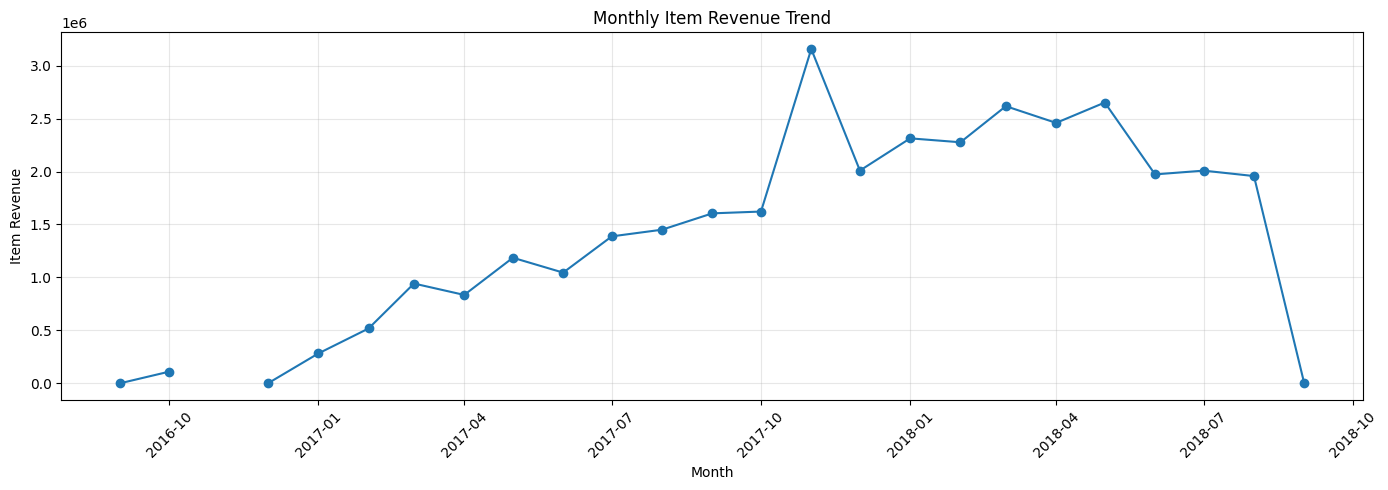

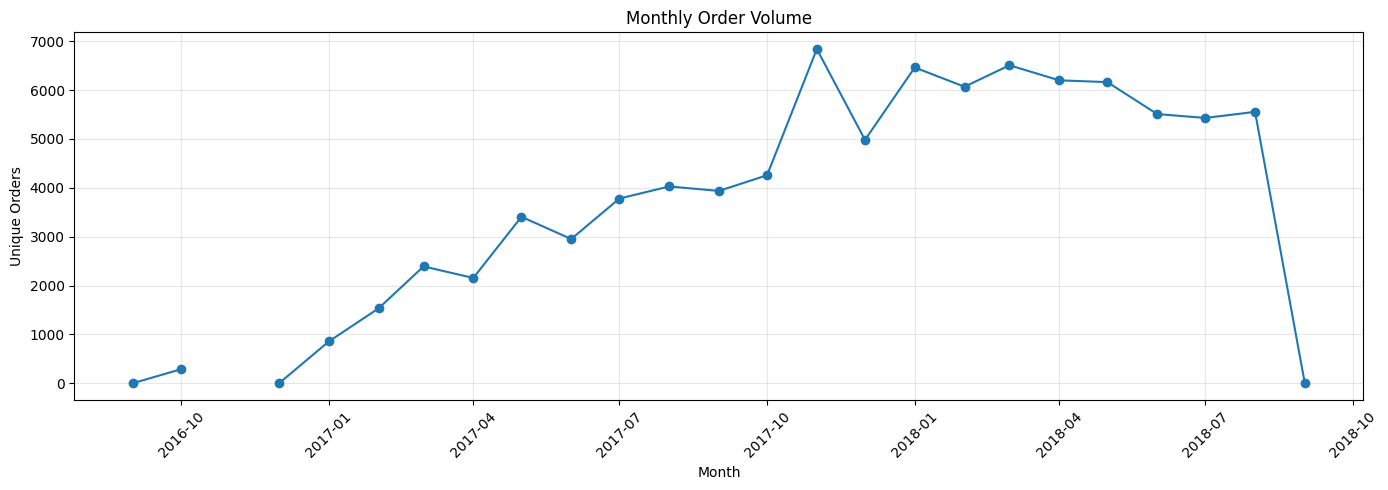

In [18]:
import matplotlib.pyplot as plt
import pandas as pd

# Prepare monthly data for plotting
monthly_plot = monthly_sales.copy()

monthly_plot["year_month"] = pd.PeriodIndex(
    monthly_plot["year_month"], freq="M"
)

# Include all calendar months so gaps remain visible
all_months = pd.period_range(
    start=df["order_date"].min().to_period("M"),
    end=df["order_date"].max().to_period("M"),
    freq="M"
)

monthly_plot = (
    monthly_plot
    .set_index("year_month")
    .reindex(all_months)
)

monthly_plot.index = monthly_plot.index.to_timestamp()

# Chart 1: Monthly item revenue
plt.figure(figsize=(14, 5))
plt.plot(
    monthly_plot.index,
    monthly_plot["total_item_revenue"],
    marker="o"
)
plt.title("Monthly Item Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Item Revenue")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Chart 2: Monthly unique orders
plt.figure(figsize=(14, 5))
plt.plot(
    monthly_plot.index,
    monthly_plot["transaction_rows"],
    marker="o"
)
plt.title("Monthly Order Volume")
plt.xlabel("Month")
plt.ylabel("Unique Orders")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
status_summary = (
    df.groupby("order_status")
    .agg(
        order_count=("order_id", "nunique"),
        item_price=("item_price", "sum"),
        shipping_charges=("shipping_charges", "sum"),
        recorded_revenue=("item_revenue", "sum")
    )
    .sort_values("recorded_revenue", ascending=False)
)

status_summary["order_percentage"] = (
    status_summary["order_count"] / df["order_id"].nunique() * 100
).round(2)

display(status_summary.round(2))

,order_count,item_price,shipping_charges,recorded_revenue,order_percentage
order_status,,,,,
delivered,87428,29925513.63,3868389.39,33793903.02,97.89
shipped,936,289169.20,42847.70,332016.90,1.05
canceled,409,96481.51,17761.10,114242.61,0.46
processing,273,71345.88,14026.33,85372.21,0.31
invoiced,266,64821.44,11996.98,76818.42,0.30
approved,2,389.03,113.31,502.34,0.00
unavailable,2,152.20,64.36,216.56,0.00


In [8]:
# Create a separate dataset containing delivered orders only
delivered_df = df[
    df["order_status"].str.strip().str.lower() == "delivered"
].copy()

print("All orders:", df["order_id"].nunique())
print("Delivered orders:", delivered_df["order_id"].nunique())

print(
    "All-status recorded revenue:",
    round(df["item_revenue"].sum(), 2)
)

print(
    "Delivered recorded revenue:",
    round(delivered_df["item_revenue"].sum(), 2)
)

print(
    "Delivered average recorded revenue per order:",
    round(
        delivered_df.groupby("order_id")["item_revenue"].sum().mean(),
        2
    )
)

All orders: 89316
Delivered orders: 87428
All-status recorded revenue: 34403072.06
Delivered recorded revenue: 33793903.02
Delivered average recorded revenue per order: 386.53


In [21]:
delivered_df.shape

(87428, 14)

In [22]:
# Monthly metrics for delivered orders only
delivered_monthly = (
    delivered_df
    .groupby(delivered_df["order_date"].dt.to_period("M"))
    .agg(
        delivered_orders=("order_id", "nunique"),
        delivered_revenue=("item_revenue", "sum")
    )
    .reset_index()
)

delivered_monthly["year_month"] = (
    delivered_monthly["order_date"].astype(str)
)

delivered_monthly = delivered_monthly.drop(
    columns=["order_date"]
)

# Find peak month for delivered revenue and order volume
peak_revenue = delivered_monthly.loc[
    delivered_monthly["delivered_revenue"].idxmax()
]

peak_orders = delivered_monthly.loc[
    delivered_monthly["delivered_orders"].idxmax()
]

print("Peak delivered revenue month:")
display(peak_revenue.to_frame().T)

print("Peak delivered order-volume month:")
display(peak_orders.to_frame().T)

# Compare November 2017
display(
    delivered_monthly[
        delivered_monthly["year_month"] == "2017-11"
    ]
)

Peak delivered revenue month:


,delivered_orders,delivered_revenue,year_month
12,6694,3106048.26,2017-11


Peak delivered order-volume month:


,delivered_orders,delivered_revenue,year_month
12,6694,3106048.26,2017-11


,delivered_orders,delivered_revenue,year_month
12,6694,3106048.26,2017-11


In [23]:
print("Top 5 months by delivered revenue:")
display(
    delivered_monthly
    .sort_values("delivered_revenue", ascending=False)
    .head(5)
    .reset_index(drop=True)
)

print("Top 5 months by delivered order volume:")
display(
    delivered_monthly
    .sort_values("delivered_orders", ascending=False)
    .head(5)
    .reset_index(drop=True)
)

Top 5 months by delivered revenue:


,delivered_orders,delivered_revenue,year_month
0,6694,3106048.26,2017-11
1,6069,2626291.37,2018-05
2,6352,2566860.87,2018-03
3,6096,2429787.27,2018-04
4,6326,2264000.84,2018-01


Top 5 months by delivered order volume:


,delivered_orders,delivered_revenue,year_month
0,6694,3106048.26,2017-11
1,6352,2566860.87,2018-03
2,6326,2264000.84,2018-01
3,6096,2429787.27,2018-04
4,6069,2626291.37,2018-05


In [24]:
delivered_monthly["avg_revenue_per_order"] = (
    delivered_monthly["delivered_revenue"]
    / delivered_monthly["delivered_orders"]
).round(2)

print("Top 5 months by average recorded revenue per delivered order:")

display(
    delivered_monthly
    .sort_values("avg_revenue_per_order", ascending=False)
    [["year_month", "delivered_orders",
      "delivered_revenue", "avg_revenue_per_order"]]
    .head(5)
    .reset_index(drop=True)
)

print("November 2017 metrics:")

display(
    delivered_monthly[
        delivered_monthly["year_month"] == "2017-11"
    ][["year_month", "delivered_orders",
       "delivered_revenue", "avg_revenue_per_order"]]
)

Top 5 months by average recorded revenue per delivered order:


,year_month,delivered_orders,delivered_revenue,avg_revenue_per_order
0,2017-11,6694,3106048.26,464.00
1,2018-05,6069,2626291.37,432.74
2,2017-09,3864,1586305.46,410.53
3,2017-12,4883,1982047.75,405.91
4,2018-03,6352,2566860.87,404.10


November 2017 metrics:


,year_month,delivered_orders,delivered_revenue,avg_revenue_per_order
12,2017-11,6694,3106048.26,464.0


In [25]:
# Monthly revenue by order status
monthly_status_revenue = (
    df.pivot_table(
        index=df["order_date"].dt.to_period("M"),
        columns="order_status",
        values="item_revenue",
        aggfunc="sum"
    )
    .sort_index()
)

monthly_status_revenue.index.name = "year_month"

print("Monthly recorded revenue by order status:")
display(monthly_status_revenue.round(2).tail(12))

Monthly recorded revenue by order status:


order_status,approved,canceled,delivered,invoiced,processing,shipped,unavailable
year_month,,,,,,,
2017-10,NaN,3933.45,1589596.94,2955.73,11151.99,14233.11,NaN
2017-11,NaN,7453.45,3106048.26,10992.64,13544.90,18427.94,NaN
2017-12,NaN,2588.08,1982047.75,3430.60,6569.34,14305.93,NaN
2018-01,NaN,6832.86,2264000.84,1498.30,10529.88,30254.88,NaN
2018-02,NaN,19238.28,2234711.36,677.68,2239.75,19177.33,NaN
2018-03,NaN,8333.94,2566860.87,7472.50,991.65,33214.73,NaN
2018-04,NaN,1901.21,2429787.27,1885.26,2345.38,23138.67,NaN
2018-05,NaN,5542.65,2626291.37,7038.20,1064.34,11437.52,NaN
2018-06,NaN,665.95,1960409.39,512.54,NaN,11234.31,NaN


In [26]:
# Reconcile monthly revenue across all order statuses
status_monthly_totals = monthly_status_revenue.sum(
    axis=1, min_count=1
)

original_monthly_totals = (
    df.groupby(df["order_date"].dt.to_period("M"))["item_revenue"]
    .sum()
)

reconciliation = pd.DataFrame({
    "status_revenue_total": status_monthly_totals,
    "original_revenue_total": original_monthly_totals
})

reconciliation["difference"] = (
    reconciliation["status_revenue_total"]
    - reconciliation["original_revenue_total"]
).round(2)

print("Maximum absolute reconciliation difference:")
print(reconciliation["difference"].abs().max())

print("\nMonths with a non-zero difference:")
display(
    reconciliation[
        reconciliation["difference"].abs() > 0.01
    ].round(2)
)

Maximum absolute reconciliation difference:
0.0

Months with a non-zero difference:


,status_revenue_total,original_revenue_total,difference


In [27]:
# Geographic performance by state
state_performance = (
    df.groupby("state")
    .agg(
        total_orders=("order_id", "nunique"),
        recorded_revenue=("item_revenue", "sum"),
        avg_revenue_per_order=("item_revenue", "mean")
    )
    .sort_values("recorded_revenue", ascending=False)
)

# Delivered-only revenue by state
delivered_state_revenue = (
    delivered_df.groupby("state")["item_revenue"]
    .sum()
    .rename("delivered_revenue")
)

state_performance = state_performance.join(
    delivered_state_revenue
)

state_performance["delivered_revenue"] = (
    state_performance["delivered_revenue"].fillna(0)
)

display(state_performance.round(2).head(10))

,total_orders,recorded_revenue,avg_revenue_per_order,delivered_revenue
state,,,,
SP,37879,14586002.19,385.07,14355295.69
RJ,11578,4347299.47,375.48,4234966.68
MG,10334,3972702.51,384.43,3928903.23
RS,4921,1884154.76,382.88,1864832.27
PR,4523,1807890.25,399.71,1778591.20
SC,3213,1210286.60,376.68,1191699.80
BA,3088,1204627.99,390.10,1182413.65
GO,1868,768086.19,411.18,747529.91
ES,1798,695583.59,386.87,689449.87


In [28]:
# Inspect the 20 highest recorded-revenue orders
high_value_orders = (
    df.nlargest(20, "item_revenue")[
        [
            "order_date",
            "order_id",
            "order_status",
            "state",
            "product_id",
            "seller_id",
            "item_price",
            "shipping_charges",
            "item_revenue",
            "product_category_name"
        ]
    ]
    .reset_index(drop=True)
)

display(high_value_orders.round(2))

,order_date,order_id,order_status,state,product_id,seller_id,item_price,shipping_charges,item_revenue,product_category_name
0,2017-11-29 21:24:02,SwjsVBeUO9OM,delivered,SP,HiyKPuVcad18,4SWsneYKnFcc,6735.0,3.82,6738.82,toys
1,2017-07-12 14:26:37,aPnggTzFcusk,delivered,SP,7tZV2OpLVZHg,nt1w9AssyxfU,6499.0,70.06,6569.06,toys
2,2018-06-05 15:30:41,PqT34ZL67pQW,delivered,PR,AQWrDq9u91NE,Q2NwKBfUdtHW,4799.0,45.76,4844.76,furniture_decor
3,2018-06-26 21:10:19,l630bFlZYRb8,delivered,SP,PCt0IOPoZaEj,Q2NwKBfUdtHW,4799.0,41.84,4840.84,furniture_decor
4,2018-06-26 21:10:19,HGcdGTihBo5U,delivered,SP,PCt0IOPoZaEj,Q2NwKBfUdtHW,4799.0,41.84,4840.84,furniture_decor
5,2018-06-26 21:10:19,aoNyeGNf0YTw,delivered,SP,PCt0IOPoZaEj,Q2NwKBfUdtHW,4799.0,41.84,4840.84,furniture_decor
6,2018-03-20 14:13:19,8kitYsDqaIKp,delivered,MG,KAJ0PDyJw1af,Q2NwKBfUdtHW,4799.0,18.67,4817.67,furniture_decor
7,2017-08-25 13:46:45,UQkobvTX3cgs,delivered,MG,ExkEUxZ1mmls,RKad98cTxhSb,4690.0,47.55,4737.55,toys
8,2018-03-01 21:54:32,fefqo629MT0H,delivered,MG,3YSqUYHtn8v3,RKad98cTxhSb,4690.0,47.55,4737.55,bed_bath_table
9,2017-03-29 10:31:33,AO5epMMj34b6,delivered,SP,PvvGFA2OcY8s,MTCYzcZ3QMv9,4590.0,89.36,4679.36,toys


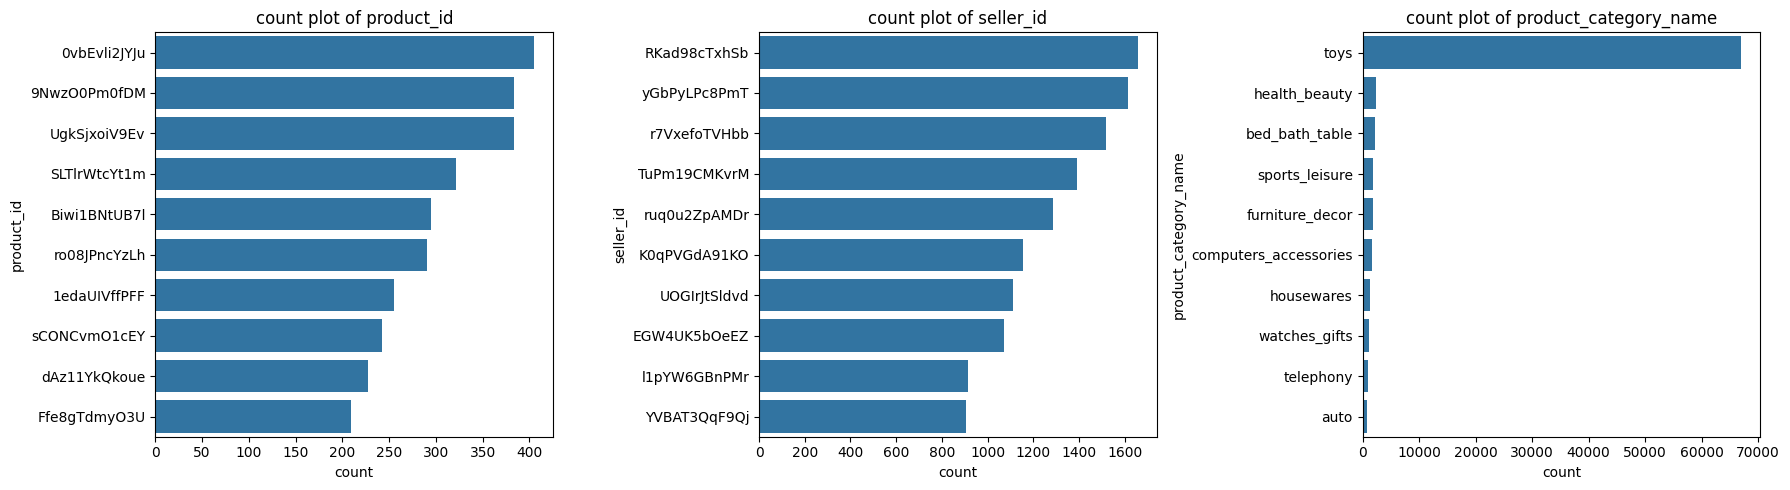

In [29]:
categorical_cols=['product_id','seller_id','product_category_name']

plt.figure(figsize=(18,5))
for i,col in enumerate(categorical_cols):
    plt.subplot(1,3,i+1)
    sns.countplot(y=df[col], data= delivered_df, order=delivered_df[col].value_counts().index[:10])
    plt.title(f"count plot of {col}")
plt.tight_layout()
plt.show()

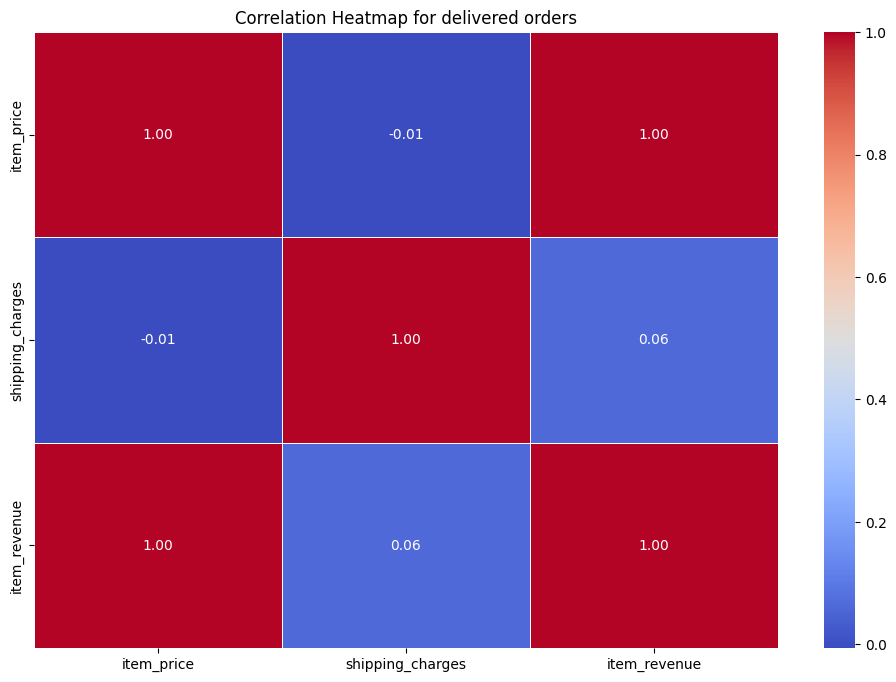

In [30]:
#correlation heatmap
plt.figure(figsize=(12,8))
correlation_matrix=delivered_df[numerical_cols].corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidth=0.5)
plt.title('Correlation Heatmap for delivered orders')
plt.show()




In [31]:
# Recalculate IQR limits for the three numerical columns
numeric_cols = [
    "item_price",
    "shipping_charges",
    "item_revenue"
]

outlier_summary = []

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = (df[col] < lower) | (df[col] > upper)

    outlier_summary.append({
        "column": col,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": int(mask.sum()),
        "outlier_pct": round(mask.mean() * 100, 2),
        "outlier_min": df.loc[mask, col].min(),
        "outlier_max": df.loc[mask, col].max(),
        "outlier_negative_count": int((df.loc[mask, col] < 0).sum())
    })

display(pd.DataFrame(outlier_summary).round(2))

,column,lower_bound,upper_bound,outlier_count,outlier_pct,outlier_min,outlier_max,outlier_negative_count
0,item_price,-449.68,908.53,5798,6.49,910.00,6735.00,0
1,shipping_charges,-35.51,112.81,4615,5.17,112.99,409.68,0
2,item_revenue,-387.52,933.08,6131,6.86,933.25,6738.82,0


In [32]:
numeric_cols = ["item_price", "shipping_charges", "item_revenue"]

outlier_summary = []

for col in numeric_cols:
    q1 = delivered_df[col].quantile(0.25)
    q3 = delivered_df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    mask = (
        (delivered_df[col] < lower) |
        (delivered_df[col] > upper)
    )

    outlier_summary.append({
        "column": col,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": int(mask.sum()),
        "outlier_pct": round(mask.mean() * 100, 2),
        "outlier_min": delivered_df.loc[mask, col].min(),
        "outlier_max": delivered_df.loc[mask, col].max()
    })

display(pd.DataFrame(outlier_summary).round(2))

,column,lower_bound,upper_bound,outlier_count,outlier_pct,outlier_min,outlier_max
0,item_price,-449.68,908.53,5713,6.53,910.00,6735.00
1,shipping_charges,-35.62,112.82,4505,5.15,112.99,409.68
2,item_revenue,-388.38,934.54,6033,6.90,934.56,6738.82


In [33]:
price_upper = (
    delivered_df["item_price"].quantile(0.75)
    + 1.5 * (
        delivered_df["item_price"].quantile(0.75)
        - delivered_df["item_price"].quantile(0.25)
    )
)

price_outliers = delivered_df[
    delivered_df["item_price"] > price_upper
].copy()

display(
    price_outliers.sort_values(
        "item_price", ascending=False
    )[
        [
            "order_date",
            "order_id",
            "order_status",
            "product_id",
            "seller_id",
            "item_price",
            "shipping_charges",
            "item_revenue",
            "product_category_name"
        ]
    ].head(20)
)

,order_date,order_id,order_status,product_id,seller_id,item_price,shipping_charges,item_revenue,product_category_name
45436,2017-11-29 21:24:02,SwjsVBeUO9OM,delivered,HiyKPuVcad18,4SWsneYKnFcc,6735.0,3.82,6738.82,toys
28299,2017-07-12 14:26:37,aPnggTzFcusk,delivered,7tZV2OpLVZHg,nt1w9AssyxfU,6499.0,70.06,6569.06,toys
15663,2018-06-26 21:10:19,l630bFlZYRb8,delivered,PCt0IOPoZaEj,Q2NwKBfUdtHW,4799.0,41.84,4840.84,furniture_decor
70683,2018-06-26 21:10:19,aoNyeGNf0YTw,delivered,PCt0IOPoZaEj,Q2NwKBfUdtHW,4799.0,41.84,4840.84,furniture_decor
61505,2018-06-26 21:10:19,HGcdGTihBo5U,delivered,PCt0IOPoZaEj,Q2NwKBfUdtHW,4799.0,41.84,4840.84,furniture_decor
26305,2018-06-05 15:30:41,PqT34ZL67pQW,delivered,AQWrDq9u91NE,Q2NwKBfUdtHW,4799.0,45.76,4844.76,furniture_decor
28208,2018-03-20 14:13:19,8kitYsDqaIKp,delivered,KAJ0PDyJw1af,Q2NwKBfUdtHW,4799.0,18.67,4817.67,furniture_decor
86143,2018-03-01 21:54:32,fefqo629MT0H,delivered,3YSqUYHtn8v3,RKad98cTxhSb,4690.0,47.55,4737.55,bed_bath_table
33362,2017-08-25 13:46:45,UQkobvTX3cgs,delivered,ExkEUxZ1mmls,RKad98cTxhSb,4690.0,47.55,4737.55,toys
34782,2017-08-31 12:50:35,eGdHDFGHmOUg,delivered,7FvOF1aKa9w7,XePbD5Ocm6Yk,4590.0,11.33,4601.33,toys


In [34]:
price_upper = (
    delivered_df["item_price"].quantile(0.75)
    + 1.5 * (
        delivered_df["item_price"].quantile(0.75)
        - delivered_df["item_price"].quantile(0.25)
    )
)

price_outliers = delivered_df[
    delivered_df["item_price"] > price_upper
].copy()

product_price_check = (
    price_outliers
    .groupby(["product_id", "product_category_name"])
    .agg(
        outlier_order_count=("order_id", "nunique"),
        min_price=("item_price", "min"),
        max_price=("item_price", "max"),
        unique_prices=("item_price", "nunique"),
        seller_count=("seller_id", "nunique")
    )
    .reset_index()
    .sort_values("outlier_order_count", ascending=False)
)

display(product_price_check.head(15))

,product_id,product_category_name,outlier_order_count,min_price,max_price,unique_prices,seller_count
274,9NwzO0Pm0fDM,toys,201,2130.00,4099.99,3,1
839,SLTlrWtcYt1m,toys,128,2130.00,4099.99,3,1
1584,ro08JPncYzLh,garden_tools,111,2130.00,4099.99,3,1
352,Biwi1BNtUB7l,toys,109,2130.00,4099.99,3,1
1046,ZWyg4uNWPHjJ,toys,109,2899.00,2899.00,1,1
155,5J7az1rwth4i,toys,103,1094.04,1094.04,1,1
1695,utVPLgd1LM3F,toys,75,1899.00,1899.00,1,1
1370,k1G4RHt3R7Nk,toys,69,1001.00,1589.00,2,1
225,7grztYpCkySJ,toys,64,1001.00,1589.00,2,1
381,CY8OZ3lT9uqB,telephony,40,2899.00,2899.00,1,1


In [35]:
print(product_price_check.columns.tolist())
display(product_price_check.head(5).to_string(index=False))

['product_id', 'product_category_name', 'outlier_order_count', 'min_price', 'max_price', 'unique_prices', 'seller_count']


'  product_id product_category_name  outlier_order_count  min_price  max_price  unique_prices  seller_count\n9NwzO0Pm0fDM                  toys                  201     2130.0    4099.99              3             1\nSLTlrWtcYt1m                  toys                  128     2130.0    4099.99              3             1\nro08JPncYzLh          garden_tools                  111     2130.0    4099.99              3             1\nBiwi1BNtUB7l                  toys                  109     2130.0    4099.99              3             1\nZWyg4uNWPHjJ                  toys                  109     2899.0    2899.00              1             1'

In [36]:
shipping_upper = (
    delivered_df["shipping_charges"].quantile(0.75)
    + 1.5 * (
        delivered_df["shipping_charges"].quantile(0.75)
        - delivered_df["shipping_charges"].quantile(0.25)
    )
)

price_upper = (
    delivered_df["item_price"].quantile(0.75)
    + 1.5 * (
        delivered_df["item_price"].quantile(0.75)
        - delivered_df["item_price"].quantile(0.25)
    )
)

high_shipping = delivered_df["shipping_charges"] > shipping_upper
high_price = delivered_df["item_price"] > price_upper

print("Delivered orders:", len(delivered_df))
print("High shipping only:", int((high_shipping & ~high_price).sum()))
print("High item price only:", int((high_price & ~high_shipping).sum()))
print("Both high shipping and high item price:", int((high_shipping & high_price).sum()))
print("Neither:", int((~high_shipping & ~high_price).sum()))

Delivered orders: 87428
High shipping only: 4244
High item price only: 5452
Both high shipping and high item price: 261
Neither: 77471


In [37]:
product_performance = (
    delivered_df
    .groupby(["product_id", "product_category_name"])
    .agg(
        order_count=("order_id", "nunique"),
        total_revenue=("item_revenue", "sum"),
        avg_revenue_per_order=("item_revenue", "mean"),
        seller_count=("seller_id", "nunique")
    )
    .reset_index()
)

# Keep products with at least one delivered order
# Rank by high average revenue per order
low_sales_high_value = product_performance[
    product_performance["order_count"] <= 5
].sort_values(
    "avg_revenue_per_order", ascending=False
)

display(low_sales_high_value.head(20).round(2))

,product_id,product_category_name,order_count,total_revenue,avg_revenue_per_order,seller_count
3391,7tZV2OpLVZHg,toys,1,6569.06,6569.06,1
4470,AQWrDq9u91NE,furniture_decor,1,4844.76,4844.76,1
10852,PCt0IOPoZaEj,furniture_decor,3,14522.52,4840.84,1
8658,KAJ0PDyJw1af,furniture_decor,1,4817.67,4817.67,1
1541,3YSqUYHtn8v3,bed_bath_table,1,4737.55,4737.55,1
6397,ExkEUxZ1mmls,toys,1,4737.55,4737.55,1
11170,PvvGFA2OcY8s,toys,1,4679.36,4679.36,1
206,0Urc5Giryip3,housewares,1,4673.09,4673.09,1
16109,bOEeiFlGwp6r,toys,2,9338.36,4669.18,1
10379,O6ZmcZrPfhZd,toys,1,4659.21,4659.21,1


In [38]:
seller_performance = (
    delivered_df
    .groupby("seller_id")
    .agg(
        order_count=("order_id", "nunique"),
        total_revenue=("item_revenue", "sum"),
        avg_revenue_per_order=("item_revenue", "mean"),
        unique_products=("product_id", "nunique")
    )
    .reset_index()
)

low_sales_high_revenue_sellers = (
    seller_performance[
        seller_performance["order_count"] <= 5
    ]
    .sort_values("total_revenue", ascending=False)
)

display(low_sales_high_revenue_sellers.head(20).round(2))

,seller_id,order_count,total_revenue,avg_revenue_per_order,unique_products
2354,pXJs8DqWkqeN,5,9715.48,1943.10,1
1027,MtTDzqNLLGhA,3,8656.56,2885.52,2
2167,lAK3blykWLaw,4,8585.34,2146.34,1
250,5zRxM0U0Jjbx,3,7132.59,2377.53,2
1100,ONP6cvQOjR7o,4,6524.93,1631.23,1
869,J284ah3IlMb9,5,6206.47,1241.29,2
948,Km0ZNSLn3NtU,4,5846.52,1461.63,4
904,JnZVO1WBU3ns,2,5829.97,2914.98,2
1495,X0ciI0pFG2dh,2,5810.30,2905.15,1
160,3f1YtqXDwmbg,5,5698.52,1139.70,2


In [39]:
seller_benchmarks = seller_performance[
    seller_performance["order_count"] > 0
]

median_orders = seller_benchmarks["order_count"].median()
median_revenue = seller_benchmarks["total_revenue"].median()

print("Median delivered orders per seller:", median_orders)
print("Median total recorded revenue per seller:", round(median_revenue, 2))

low_volume_high_revenue = seller_benchmarks[
    (seller_benchmarks["order_count"] <= median_orders) &
    (seller_benchmarks["total_revenue"] > median_revenue)
].sort_values("total_revenue", ascending=False)

display(low_volume_high_revenue.head(20).round(2))

Median delivered orders per seller: 7.0
Median total recorded revenue per seller: 2028.58


,seller_id,order_count,total_revenue,avg_revenue_per_order,unique_products
1689,auOjPE1U7wEB,6,17482.96,2913.83,2
2210,mEBm4Hehu6HT,6,14297.81,2382.97,2
858,Irp7Dmt10BAO,6,11541.70,1923.62,5
1658,aGKHuILL8ojO,7,10218.21,1459.74,3
2354,pXJs8DqWkqeN,5,9715.48,1943.10,1
2720,xbN5skgn2okE,6,9600.22,1600.04,3
1106,ORcmroQxutFQ,7,8864.63,1266.38,3
1027,MtTDzqNLLGhA,3,8656.56,2885.52,2
2167,lAK3blykWLaw,4,8585.34,2146.34,1
250,5zRxM0U0Jjbx,3,7132.59,2377.53,2


In [40]:
top_seller_ids = low_volume_high_revenue.head(10)["seller_id"]

top_seller_products = (
    delivered_df[
        delivered_df["seller_id"].isin(top_seller_ids)
    ]
    .groupby(["seller_id", "product_id", "product_category_name"])
    .agg(
        order_count=("order_id", "nunique"),
        total_revenue=("item_revenue", "sum"),
        avg_revenue_per_order=("item_revenue", "mean")
    )
    .reset_index()
    .sort_values(
        ["seller_id", "total_revenue"],
        ascending=[True, False]
    )
)

display(top_seller_products.round(2))

,seller_id,product_id,product_category_name,order_count,total_revenue,avg_revenue_per_order
1,5zRxM0U0Jjbx,yQuko6FKuHy9,toys,2,6927.56,3463.78
0,5zRxM0U0Jjbx,DqGU9xjO9BxF,health_beauty,1,205.03,205.03
6,Irp7Dmt10BAO,okwWiFyh4HWR,toys,2,7448.36,3724.18
4,Irp7Dmt10BAO,VyCf5it8YfW1,toys,1,2146.85,2146.85
3,Irp7Dmt10BAO,KbZH90QlcT87,toys,1,1226.77,1226.77
2,Irp7Dmt10BAO,ATR5moHTh2u6,toys,1,621.81,621.81
5,Irp7Dmt10BAO,dOTG4bXWSOhk,toys,1,97.91,97.91
7,MtTDzqNLLGhA,0tvIWfaaCkcv,costruction_tools_garden,2,8282.80,4141.40
8,MtTDzqNLLGhA,bI6X8El6CIZv,toys,1,373.76,373.76
9,ORcmroQxutFQ,SLrCG8IDgvMY,toys,5,4987.63,997.53


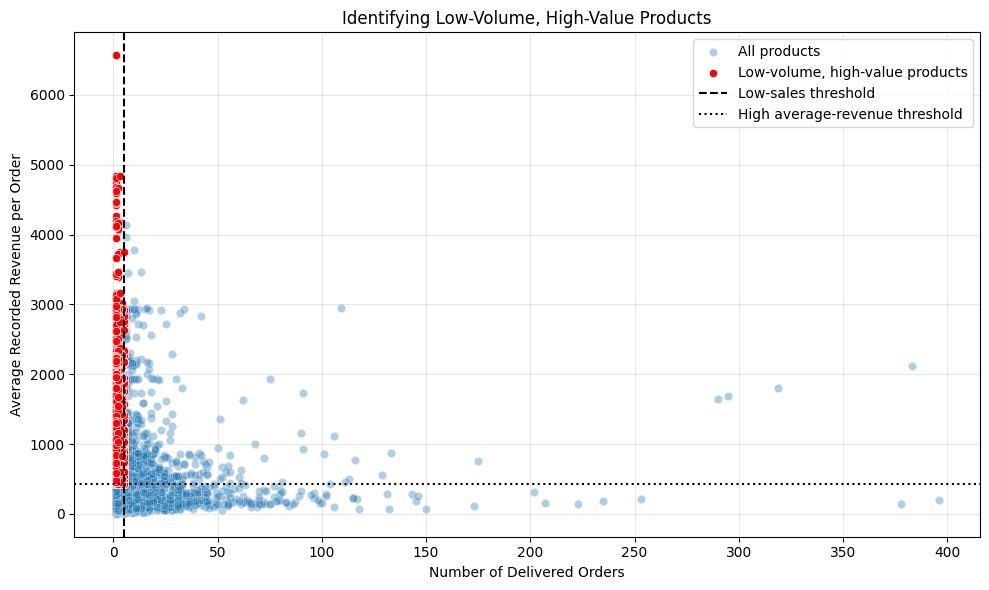

In [41]:

import matplotlib.pyplot as plt
import seaborn as sns

# Use product_performance created earlier
# Define low sales as 5 or fewer orders
low_sales_threshold = 5

# Use the 75th percentile of average revenue as the high-value threshold
high_revenue_threshold = product_performance[
    "avg_revenue_per_order"
].quantile(0.75)

target_products = product_performance[
    (product_performance["order_count"] <= low_sales_threshold) &
    (product_performance["avg_revenue_per_order"] >= high_revenue_threshold)
]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=product_performance,
    x="order_count",
    y="avg_revenue_per_order",
    alpha=0.35,
    label="All products"
)

sns.scatterplot(
    data=target_products,
    x="order_count",
    y="avg_revenue_per_order",
    color="red",
    label="Low-volume, high-value products"
)

plt.axvline(
    low_sales_threshold,
    linestyle="--",
    color="black",
    label="Low-sales threshold"
)

plt.axhline(
    high_revenue_threshold,
    linestyle=":",
    color="black",
    label="High average-revenue threshold"
)

plt.xlabel("Number of Delivered Orders")
plt.ylabel("Average Recorded Revenue per Order")
plt.title("Identifying Low-Volume, High-Value Products")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [42]:

top_target_products = (
    target_products
    .sort_values(
        ["avg_revenue_per_order", "total_revenue"],
        ascending=False
    )
    .head(10)
)

display(
    top_target_products[
        [
            "product_id",
            "product_category_name",
            "order_count",
            "total_revenue",
            "avg_revenue_per_order",
            "seller_count"
        ]
    ].round(2)
)


,product_id,product_category_name,order_count,total_revenue,avg_revenue_per_order,seller_count
3391,7tZV2OpLVZHg,toys,1,6569.06,6569.06,1
4470,AQWrDq9u91NE,furniture_decor,1,4844.76,4844.76,1
10852,PCt0IOPoZaEj,furniture_decor,3,14522.52,4840.84,1
8658,KAJ0PDyJw1af,furniture_decor,1,4817.67,4817.67,1
1541,3YSqUYHtn8v3,bed_bath_table,1,4737.55,4737.55,1
6397,ExkEUxZ1mmls,toys,1,4737.55,4737.55,1
11170,PvvGFA2OcY8s,toys,1,4679.36,4679.36,1
206,0Urc5Giryip3,housewares,1,4673.09,4673.09,1
16109,bOEeiFlGwp6r,toys,2,9338.36,4669.18,1
10379,O6ZmcZrPfhZd,toys,1,4659.21,4659.21,1


In [43]:

category_performance = (
    delivered_df.groupby("product_category_name")
    .agg(
        total_orders=("order_id", "nunique"),
        total_revenue=("item_revenue", "sum"),
        unique_products=("product_id", "nunique"),
        avg_revenue_per_order=("item_revenue", "mean")
    )
    .reset_index()
    .sort_values("total_revenue", ascending=False)
)

display(category_performance.head(15).round(2))


,product_category_name,total_orders,total_revenue,unique_products,avg_revenue_per_order
69,toys,65643,25536427.98,20175,389.02
39,furniture_decor,1723,815791.38,550,473.47
42,garden_tools,777,764689.13,142,984.16
8,bed_bath_table,2119,688112.99,648,324.73
43,health_beauty,2289,680047.93,516,297.09
70,watches_gifts,1177,628620.42,261,534.09
65,sports_leisure,1799,606826.50,614,337.31
68,telephony,891,525245.59,252,589.50
15,computers_accessories,1673,494878.76,352,295.80
49,housewares,1301,463134.90,496,355.98


In [44]:

category_thresholds = {
    "median_orders": category_performance["total_orders"].median(),
    "median_avg_revenue": category_performance[
        "avg_revenue_per_order"
    ].median()
}

category_opportunities = category_performance[
    (category_performance["total_orders"] < category_thresholds["median_orders"]) &
    (category_performance["avg_revenue_per_order"] > category_thresholds["median_avg_revenue"])
].sort_values("avg_revenue_per_order", ascending=False)

print("Median category order count:", category_thresholds["median_orders"])
print("Median average revenue per order:", round(category_thresholds["median_avg_revenue"], 2))

display(category_opportunities.round(2))


Median category order count: 65.0
Median average revenue per order: 324.31


,product_category_name,total_orders,total_revenue,unique_products,avg_revenue_per_order
52,la_cuisine,4,5354.04,3,1338.51
46,home_comfort_2,1,743.96,1,743.96
4,arts_and_craftmanship,4,2428.39,4,607.10
33,fashion_underwear_beach,15,7828.72,9,521.91
18,construction_tools_lights,51,25870.34,19,507.26
47,home_confort,40,16880.30,19,422.01
31,fashion_shoes,60,24857.84,35,414.30
29,fashion_childrens_clothes,2,720.20,1,360.10
67,tablets_printing_image,64,22368.68,4,349.51
34,fixed_telephony,46,16038.59,29,348.66


In [45]:

# Examine products within the categories identified above
opportunity_categories = category_opportunities[
    "product_category_name"
].tolist()

category_product_detail = (
    delivered_df[
        delivered_df["product_category_name"].isin(opportunity_categories)
    ]
    .groupby(["product_category_name", "product_id"])
    .agg(
        order_count=("order_id", "nunique"),
        total_revenue=("item_revenue", "sum"),
        avg_revenue_per_order=("item_revenue", "mean")
    )
    .reset_index()
    .sort_values(
        ["product_category_name", "total_revenue"],
        ascending=[True, False]
    )
)

display(category_product_detail.round(2))


,product_category_name,product_id,order_count,total_revenue,avg_revenue_per_order
4,art,SxshRarIkiHQ,2,1864.17,932.08
3,art,Lz4jn6vRdWuq,1,638.87,638.87
9,art,obBiFSPa8ARm,1,573.84,573.84
10,art,vAQywptdWSJv,1,290.37,290.37
0,art,1BYVcPiYG0M3,1,259.45,259.45
...,...,...,...,...,...
144,la_cuisine,TU5Y707rHnhi,1,107.71,107.71
146,tablets_printing_image,FlMuTHJ7O6S8,21,13103.95,624.00
148,tablets_printing_image,pcc1vTlRqasQ,27,6509.37,241.09
147,tablets_printing_image,QFTWw9VD2QzH,15,2482.00,165.47


In [46]:

# Benchmark average revenue against all products in the selected categories
median_product_avg_revenue = category_product_detail[
    "avg_revenue_per_order"
].median()

established_high_value_products = category_product_detail[
    (category_product_detail["order_count"] >= 10) &
    (category_product_detail["avg_revenue_per_order"] > median_product_avg_revenue)
].sort_values(
    "total_revenue",
    ascending=False
)

print(
    "Median product average recorded revenue:",
    round(median_product_avg_revenue, 2)
)

display(established_high_value_products.head(15).round(2))


Median product average recorded revenue: 231.84


,product_category_name,product_id,order_count,total_revenue,avg_revenue_per_order
25,construction_tools_lights,gJs1bkBcGmQD,11,15753.55,1432.14
146,tablets_printing_image,FlMuTHJ7O6S8,21,13103.95,624.00
36,costruction_tools_tools,53oIZTq7pEol,11,7839.50,712.68
148,tablets_printing_image,pcc1vTlRqasQ,27,6509.37,241.09
76,fashion_shoes,x4Bt2TMquDEg,10,5434.58,543.46


In [4]:
df_canceled=df[df['order_status']=='canceled'].copy()

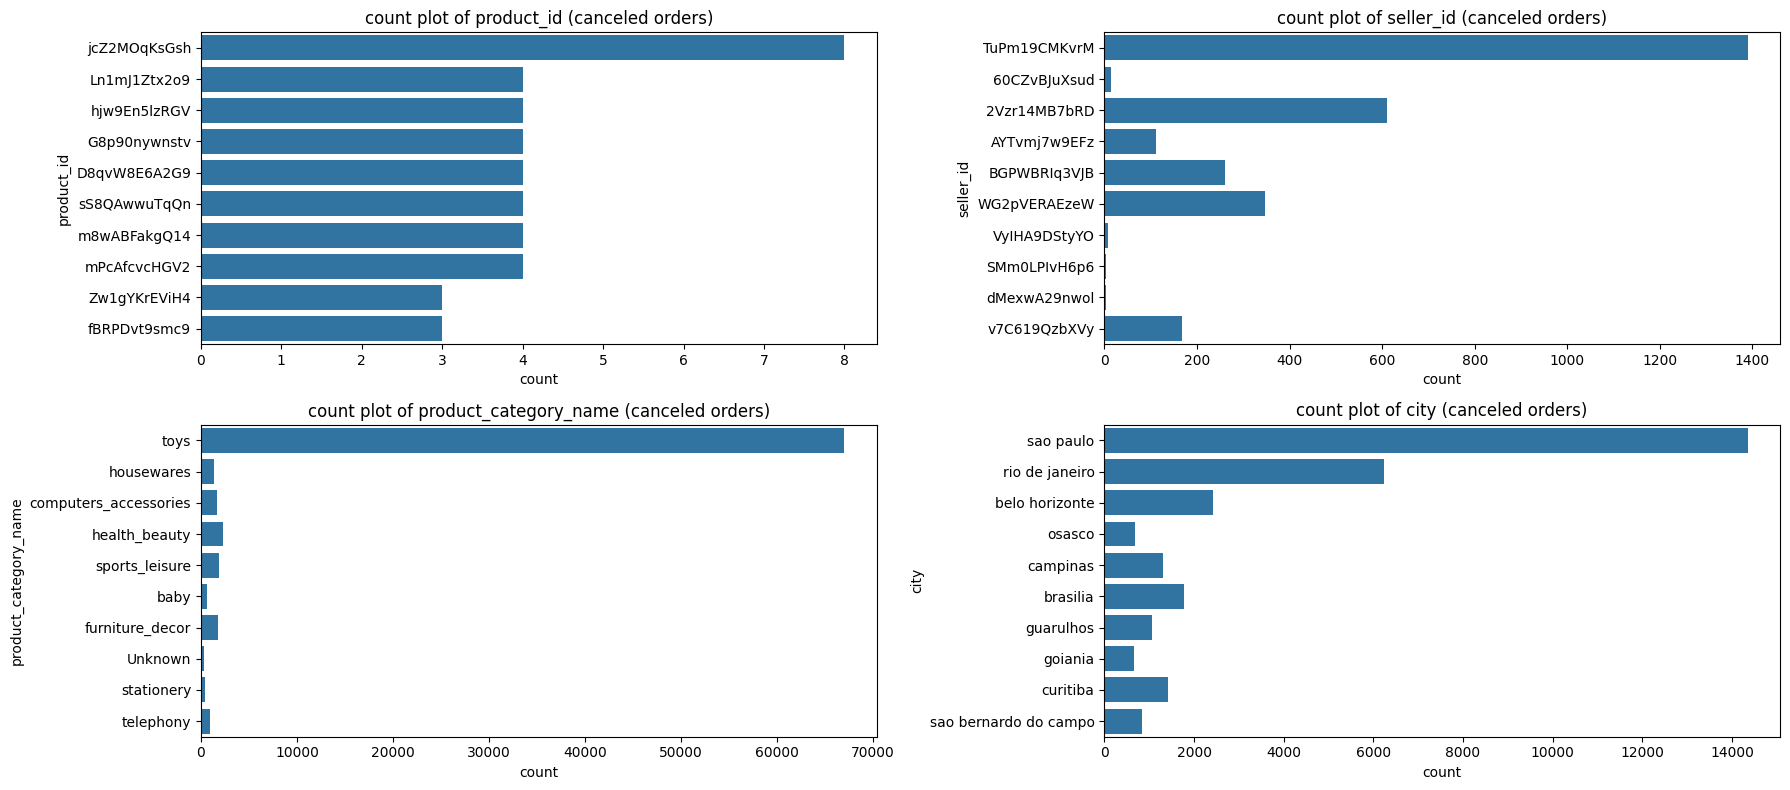

In [5]:
categorical_cols=['product_id','seller_id','product_category_name','city']

plt.figure(figsize=(18,8))
for i,col in enumerate(categorical_cols):
    plt.subplot(2,2,i+1)
    sns.countplot(y=df[col], data= df_canceled, order=df_canceled[col].value_counts().index[:10])
    plt.title(f"count plot of {col} (canceled orders)")
plt.tight_layout()
plt.show()

In [6]:
df_canceled.shape

(409, 12)

In [9]:
delivered_df.shape

(87428, 12)

In [10]:
df.shape

(89316, 12)

In [89]:
delivered_orders=df_delivered.groupby("order_status").agg({'total_cost':'sum','profit':'sum','total_sales':'sum'}).reset_index()

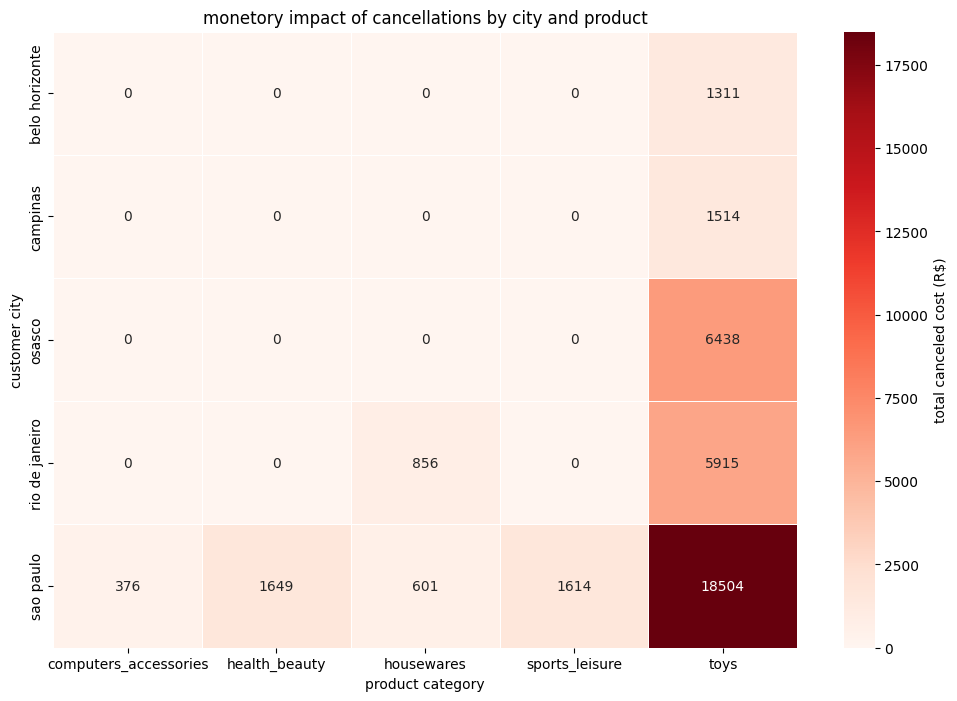

In [11]:
top_products1= df_canceled['product_category_name'].value_counts().index[:5]
top_cities= df_canceled['city'].value_counts().index[:5]
df_pivot=df_canceled[df_canceled['product_category_name'].isin(top_products1) & df_canceled['city'].isin(top_cities)]

cost_matrix=df_pivot.groupby(['city','product_category_name',])['item_revenue'].sum().unstack(fill_value=0)
plt.figure(figsize=(12,8))
sns.heatmap(cost_matrix, annot=True, fmt=".0f", cmap="Reds", linewidths=0.5, cbar_kws={'label':'total canceled cost (R$)'})
plt.title("monetory impact of cancellations by city and product")
plt.xlabel('product category')
plt.ylabel('customer city')
plt.show()

In [12]:
df_canceled.nunique

<bound method DataFrame.nunique of                  city state order_status           order_date      order_id  \
15          sao paulo    SP     canceled  2017-07-24 11:38:43  P5R6jr1qZdh4   
89          sao paulo    SP     canceled  2017-07-29 12:56:17  2HQ26ShSPhCA   
133     monte carmelo    MG     canceled  2017-11-06 15:47:20  1By8LOosrvF2   
139        buenopolis    MG     canceled  2018-07-04 16:05:56  70G4cTVwm38h   
146          teresina    PI     canceled  2018-02-05 16:30:33  aDxB5SgA7C4q   
...               ...   ...          ...                  ...           ...   
89082       sao paulo    SP     canceled  2017-08-16 16:15:31  aG78pToOaDfa   
89136  belo horizonte    MG     canceled  2017-09-15 09:29:20  21GpVhZQJGfP   
89165      sao carlos    SP     canceled  2017-11-14 21:58:32  sjtJ9gzepMyS   
89226         jundiai    SP     canceled  2017-08-02 14:08:18  0jPFvDPItbRN   
89262       sao paulo    SP     canceled  2017-12-13 12:55:38  rnnNWGgyHsA5   

         product